In [ ]:
# 1. Import Pandas
import pandas as pd

# 2. Create sample dataset
data = {
    "Student_ID": ["S001", "S002", "S003", "S004", "S005", "S005"],
    "Age": [19, 20, 19, 21, 20, 20],
    "Department": [
        "Data Science",
        "BCA",
        "Data Science",
        "BBA",
        "BCA",
        "BCA"
    ],
    "Marks": [82, 76, 91, 68, 85, 85],
    "Attendance": [90, 85, 95, None, 88, 88]
}

df = pd.DataFrame(data)

# 3. View the dataset
df

# 4. First five rows
df.head()

# 5. Last five rows
df.tail()

# 6. Dataset dimensions
df.shape

# 7. Dataset information
df.info()

# 8. Check missing values
df.isnull().sum()

# 9. Check duplicate rows
df.duplicated().sum()

# 10. Display duplicate rows
df[df.duplicated()]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Student_ID  6 non-null      object 
 1   Age         6 non-null      int64  
 2   Department  6 non-null      object 
 3   Marks       6 non-null      int64  
 4   Attendance  5 non-null      float64
dtypes: float64(1), int64(2), object(2)
memory usage: 372.0+ bytes


,Student_ID,Age,Department,Marks,Attendance
5,S005,20,BCA,85,88.0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
marks = [45, 50, 52, 55, 60, 62, 65, 68,
         70, 72, 75, 78, 80, 85, 95, 150]

df = pd.DataFrame({"Marks": marks})

# Measures of center
print("Mean:", df["Marks"].mean())
print("Median:", df["Marks"].median())

# Measures of spread
print("Variance:", df["Marks"].var())
print("Standard Deviation:", df["Marks"].std())

# Quartiles
Q1 = df["Marks"].quantile(0.25)
Q3 = df["Marks"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

# Outlier boundaries
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Bound:", lower)
print("Upper Bound:", upper)

# Outliers
outliers = df[
    (df["Marks"] < lower) |
    (df["Marks"] > upper)
]

print("Outliers:")
print(outliers)

Mean: 72.625
Median: 69.0
Variance: 606.65
Standard Deviation: 24.63026593441492
Q1: 58.75
Q3: 78.5
IQR: 19.75
Lower Bound: 29.125
Upper Bound: 108.125
Outliers:
    Marks
15    150


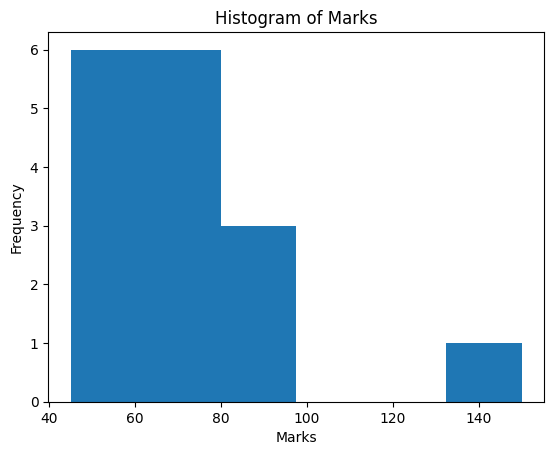

In [ ]:
plt.hist(df["Marks"], bins=6)

plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.title("Histogram of Marks")

plt.show()

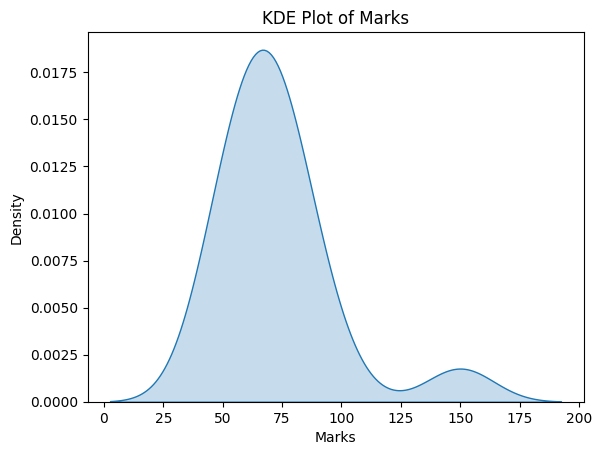

In [ ]:
sns.kdeplot(df["Marks"], fill=True)

plt.xlabel("Marks")
plt.title("KDE Plot of Marks")

plt.show()

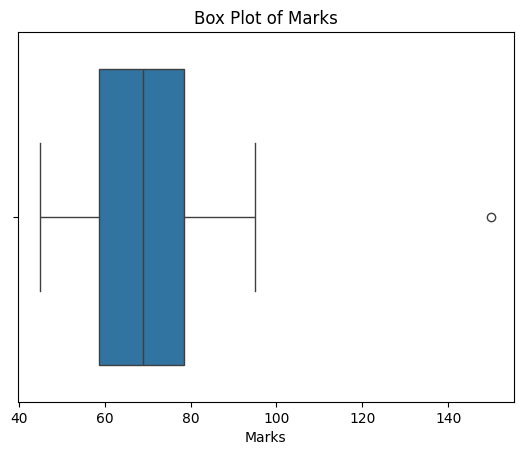

In [ ]:
sns.boxplot(x=df["Marks"])

plt.xlabel("Marks")
plt.title("Box Plot of Marks")

plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Study_Hours": [1,2,3,4,5,6,7,8,9,10],
    "Exam_Score": [42,48,55,60,65,70,76,82,88,94],
    "Department": [
        "Sales", "Sales",
        "Operations", "Operations",
        "Engineering", "Engineering",
        "Sales", "Operations",
        "Engineering", "Engineering"
    ],
    "Salary": [
        40000, 45000,
        48000, 52000,
        60000, 65000,
        46000, 54000,
        68000, 72000
    ]
}

df = pd.DataFrame(data)

print(df)

   Study_Hours  Exam_Score   Department  Salary
0            1          42        Sales   40000
1            2          48        Sales   45000
2            3          55   Operations   48000
3            4          60   Operations   52000
4            5          65  Engineering   60000
5            6          70  Engineering   65000
6            7          76        Sales   46000
7            8          82   Operations   54000
8            9          88  Engineering   68000
9           10          94  Engineering   72000


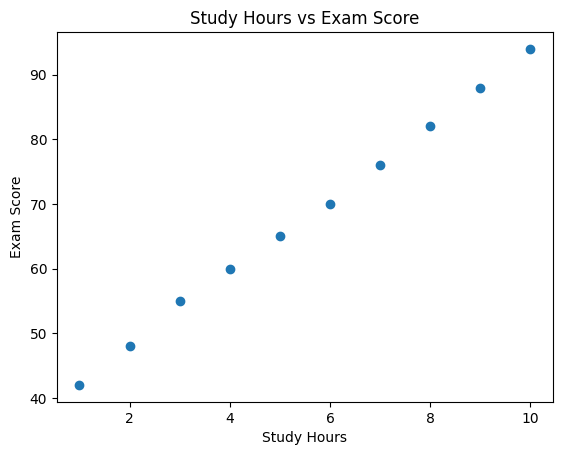

In [ ]:
plt.scatter(
    df["Study_Hours"],
    df["Exam_Score"]
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.show()

In [ ]:
r = df["Study_Hours"].corr(
    df["Exam_Score"]
)

print("Pearson's r =", r)

Pearson's r = 0.9994047068680404


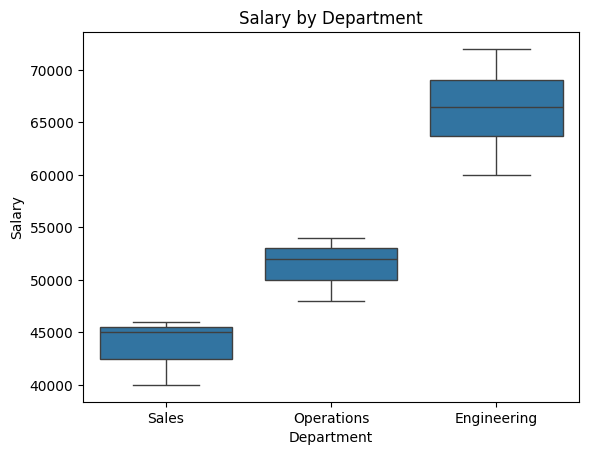

In [ ]:
sns.boxplot(
    x="Department",
    y="Salary",
    data=df
)

plt.title("Salary by Department")
plt.show()

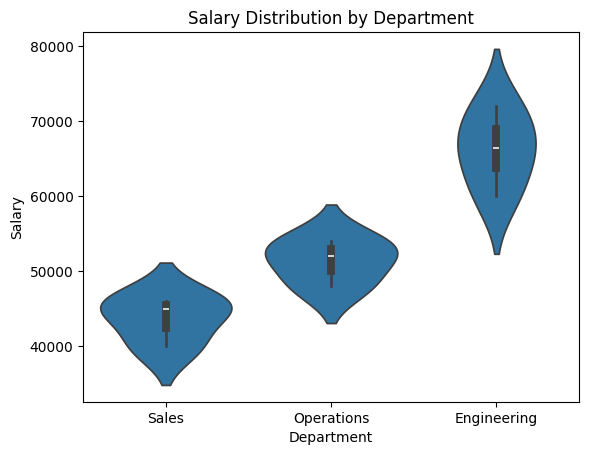

In [ ]:
sns.violinplot(
    x="Department",
    y="Salary",
    data=df
)

plt.title("Salary Distribution by Department")
plt.show()

In [ ]:
cross_tab = pd.crosstab(
    df["Department"],
    pd.cut(
        df["Salary"],
        bins=3,
        labels=["Low", "Medium", "High"]
    )
)

print(cross_tab)

Salary       Low  Medium  High
Department                    
Engineering    0       1     3
Operations     1       2     0
Sales          3       0     0


In [ ]:
import pandas as pd

data = {
    "Region": ["North", "North", "South", "South", "West", "West"],
    "Product": ["Electronics", "Apparel", "Electronics",
                "Apparel", "Electronics", "Apparel"],
    "Sales": [42300, 28150, 36900, 31400, 51200, 26700]
}

df = pd.DataFrame(data)

print(df)

  Region      Product  Sales
0  North  Electronics  42300
1  North      Apparel  28150
2  South  Electronics  36900
3  South      Apparel  31400
4   West  Electronics  51200
5   West      Apparel  26700


In [ ]:
df.groupby("Region")["Sales"].mean()

,Sales
Region,
North,35225.0
South,34150.0
West,38950.0


In [ ]:
df.groupby(["Region", "Product"])["Sales"].mean()

Region  Product    
North   Apparel        28150.0
        Electronics    42300.0
South   Apparel        31400.0
        Electronics    36900.0
West    Apparel        26700.0
        Electronics    51200.0
Name: Sales, dtype: float64

In [ ]:
df.groupby("Region")["Sales"].agg(
    ["mean", "sum", "min", "max", "count"]
)

,mean,sum,min,max,count
Region,,,,,
North,35225.0,70450,28150,42300,2
South,34150.0,68300,31400,36900,2
West,38950.0,77900,26700,51200,2


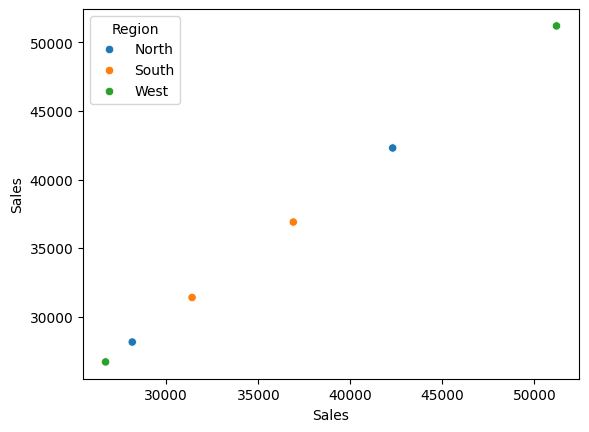

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x="Sales",
    y="Sales",
    hue="Region"
)

plt.show()

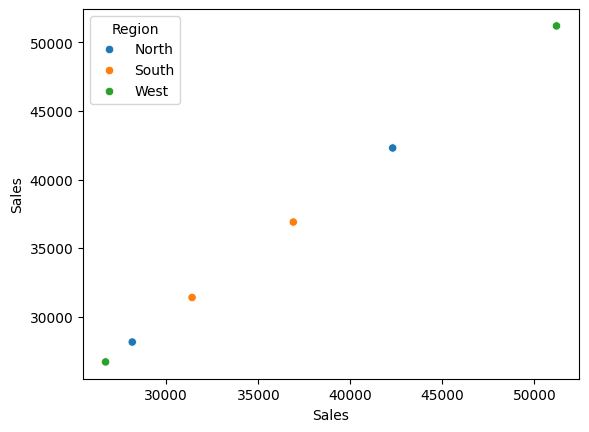

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x="Sales",
    y="Sales",
    hue="Region"
)

plt.show()

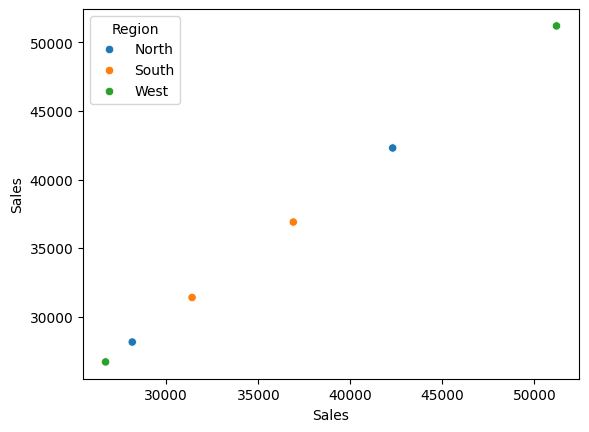

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x="Sales",
    y="Sales",
    hue="Region"
)

plt.show()

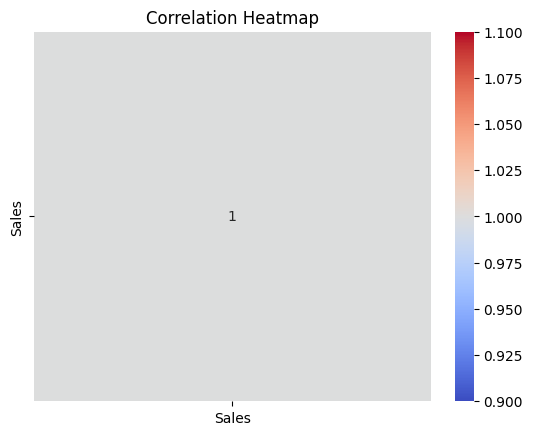

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

For a richer heatmap with more variables, I will use a different dataset. This dataset includes 'Study_Hours', 'Exam_Score', and 'Salary'.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data_rich = {
    "Study_Hours": [1,2,3,4,5,6,7,8,9,10],
    "Exam_Score": [42,48,55,60,65,70,76,82,88,94],
    "Department": [
        "Sales", "Sales",
        "Operations", "Operations",
        "Engineering", "Engineering",
        "Sales", "Operations",
        "Engineering", "Engineering"
    ],
    "Salary": [
        40000, 45000,
        48000, 52000,
        60000, 65000,
        46000, 54000,
        68000, 72000
    ]
}

df_rich = pd.DataFrame(data_rich)
display(df_rich.head())

,Study_Hours,Exam_Score,Department,Salary
0,1,42,Sales,40000
1,2,48,Sales,45000
2,3,55,Operations,48000
3,4,60,Operations,52000
4,5,65,Engineering,60000


Now, let's create a correlation heatmap for this new `df_rich` DataFrame.

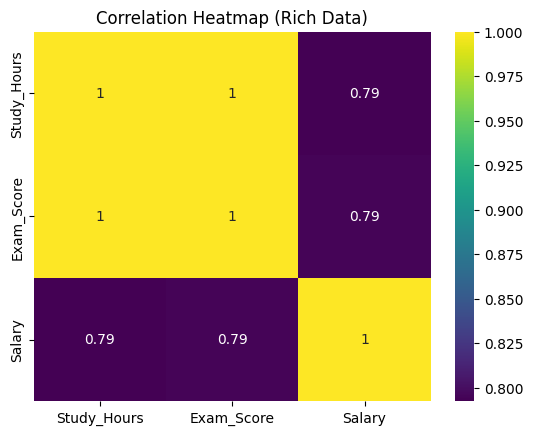

In [ ]:
correlation_rich = df_rich.corr(numeric_only=True)

sns.heatmap(
    correlation_rich,
    annot=True,
    cmap="viridis" # Using a different colormap for distinct colors
)

plt.title("Correlation Heatmap (Rich Data)")
plt.show()

In [ ]:
annot=True

In [ ]:
cmap="coolwarm"

ValueError: Could not interpret value `Size` for `x`. An entry with this name does not appear in `data`.

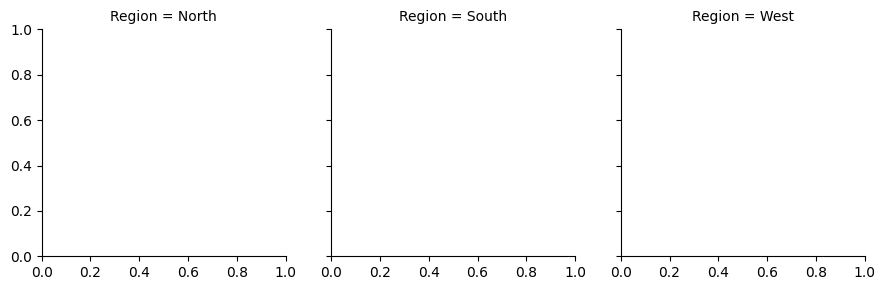

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.FacetGrid(
    df,
    col="Region"
)

g.map_dataframe(
    sns.scatterplot,
    x="Size",
    y="Price"
)

plt.show()

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "Age": [20, 21, 20, 22],
    "Marks": [78, 85, None, 91]
})

# Mean imputation
df["Marks"] = df["Marks"].fillna(df["Marks"].mean())

print(df)

   Age      Marks
0   20  78.000000
1   21  85.000000
2   20  84.666667
3   22  91.000000


In [ ]:
df = df.dropna()

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "City": ["NY", "new york ", "N.Y.", "ny", "Boston"]
})

df["City"] = df["City"].str.strip().str.lower()

df["City"] = df["City"].replace({
    "ny": "New York",
    "n.y.": "New York",
    "new york": "New York"
})

print(df)

       City
0  New York
1  New York
2  New York
3  New York
4    boston


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
data = {
    "Department": [
        "Sales", "Sales", "Sales",
        "HR", "HR", "HR",
        "IT", "IT", "IT",
        "Finance", "Finance", "Finance"
    ],

    "Satisfaction": [
        8, 7, None,
        6, 5, 7,
        9, 8, 9,
        7, 6, 8
    ],

    "Complaints": [
        2, 3, 4,
        5, 6, 4,
        1, 2, 1,
        3, 4, 2
    ]
}

df = pd.DataFrame(data)

print(df)

   Department  Satisfaction  Complaints
0       Sales           8.0           2
1       Sales           7.0           3
2       Sales           NaN           4
3          HR           6.0           5
4          HR           5.0           6
5          HR           7.0           4
6          IT           9.0           1
7          IT           8.0           2
8          IT           9.0           1
9     Finance           7.0           3
10    Finance           6.0           4
11    Finance           8.0           2


In [ ]:
print(df.isnull().sum())

Department      0
Satisfaction    1
Complaints      0
dtype: int64


In [ ]:
df["Satisfaction"] = df["Satisfaction"].fillna(
    df["Satisfaction"].median()
)

In [ ]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Department    12 non-null     object 
 1   Satisfaction  12 non-null     float64
 2   Complaints    12 non-null     int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 420.0+ bytes
None
       Satisfaction  Complaints
count     12.000000   12.000000
mean       7.250000    3.083333
std        1.215431    1.564279
min        5.000000    1.000000
25%        6.750000    2.000000
50%        7.000000    3.000000
75%        8.000000    4.000000
max        9.000000    6.000000


In [ ]:
department_avg = df.groupby("Department")["Satisfaction"].mean()

print(department_avg)

Department
Finance    7.000000
HR         6.000000
IT         8.666667
Sales      7.333333
Name: Satisfaction, dtype: float64


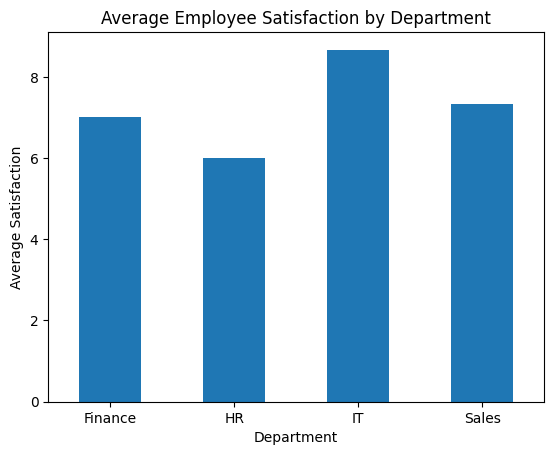

In [ ]:
department_avg.plot(kind="bar")

plt.title("Average Employee Satisfaction by Department")
plt.xlabel("Department")
plt.ylabel("Average Satisfaction")
plt.xticks(rotation=0)

plt.show()